# 本机部署实践：Qwen3.5-2B

基于 Hugging Face Transformers，在本机部署 **Qwen3.5-2B**（原生多模态小模型），走通「分词器 → 文本推理 → 图像推理」的完整链路。

| 项目 | 值 |
|---|---|
| 模型目录 | `D:\project\step1\week20\Qwen3.5-2B`（bf16，约 4.55GB） |
| 显卡 | RTX 3060 Laptop（6GB 显存）→ `device_map="auto"` 自动适配 |
| 内核环境 | `D:\project\step3\llm`（torch 2.10.0+cu128 · transformers 5.16.1 · torchvision 0.25.0） |

**流程**：分词器 → 分词练习 → 加载模型 → 文本对话 → 图像理解

## 🛠️ 计时工具

定义一个 `@timer` 装饰器：把推理函数（文本对话、图像理解等）包上它，调用时自动打印耗时。

In [10]:
# 计时装饰器：包住任意函数，自动打印它的运行耗时
import time
from functools import wraps


def timer(func):
    @wraps(func)
    def wrapper(*args, **kwargs):
        t0 = time.perf_counter()
        result = func(*args, **kwargs)
        cost = time.perf_counter() - t0
        print(f"⏱️ {func.__name__} 耗时: {cost:.2f} 秒")
        return result
    return wrapper

In [7]:
# ============ 1. 加载分词器与处理器 ============
from transformers import AutoTokenizer, AutoProcessor

MODEL_DIR = r"D:\project\step1\week20\Qwen3.5-2B"

tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR)   # 管文本：分词 / 编码 / 解码
processor = AutoProcessor.from_pretrained(MODEL_DIR)   # 管多模态：文本 + 图像 + 视频

print("词表大小:", tokenizer.vocab_size)
print("处理器类型:", type(processor).__name__)

词表大小: 248044
处理器类型: Qwen3VLProcessor


## 2️⃣ 分词器练习

核心四步：`tokenize` 切词 → `convert_tokens_to_ids` 查 id → `encode`/`decode` 往返 → 批量编码（`padding` 补齐 + `truncation` 截断）。

In [6]:
# ============ 2. 分词器练习 ============
sen = "真术相成，值得信赖！"

# ① 切词
# 注：Qwen 是 byte-level BPE，token 是"字节级映射字符"（打印出来像乱码是正常的），decode 能还原成原文
tokens = tokenizer.tokenize(sen)
print("① tokenize 切词:", tokens)

# ② token ↔ id 正反向转换
ids = tokenizer.convert_tokens_to_ids(tokens)
print("② token -> id:", ids)
print("③ id -> token:", tokenizer.convert_ids_to_tokens(ids))

# ④ encode / decode 往返
encoded = tokenizer.encode(sen)
print("④ encode 编码:", encoded)
print("⑤ decode 解码:", tokenizer.decode(encoded))

# ⑥ 批量编码：短句 padding 补齐到 15，长句 truncation 截断
batch_sentences = [
    "真术相成真的很好",
    "真术相成，值得信赖",
    "期待我们在真术相成相遇，一起变得更美好",
]
batch = tokenizer(batch_sentences, max_length=15, padding="max_length", truncation=True)
print("⑥ 批量 input_ids:")
for line in tokenizer.batch_decode(batch["input_ids"]):
    print("   ", repr(line))

① tokenize 切词: ['çľŁ', 'æľ¯', 'çĽ¸', 'æĪĲ', 'ï¼Į', 'åĢ¼å¾Ĺä¿¡èµĸ', 'ï¼ģ']
② token -> id: [96196, 96113, 96011, 95873, 3709, 125506, 6115]
③ id -> token: ['çľŁ', 'æľ¯', 'çĽ¸', 'æĪĲ', 'ï¼Į', 'åĢ¼å¾Ĺä¿¡èµĸ', 'ï¼ģ']
④ encode 编码: [96196, 96113, 96011, 95873, 3709, 125506, 6115]
⑤ decode 解码: 真术相成，值得信赖！
⑥ 批量 input_ids:
    '真术相成真的很好<|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|>'
    '真术相成，值得信赖<|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|><|endoftext|>'
    '期待我们在真术相成相遇，一起变得更美好<|endoftext|><|endoftext|><|endoftext|><|endoftext|>'


## 3️⃣ 加载模型（6GB 显存适配）

两个关键参数：

- `dtype="auto"`：按权重原始精度（bf16）加载——**不能用默认的 fp32**，否则 4.5GB 权重会膨胀成 9GB 直接爆显存
- `device_map="auto"`：交给 accelerate 自动摆放，先塞满 GPU、放不下的层回落 CPU 内存

> 首次加载要读 4.5GB 权重文件，约 1~2 分钟。

In [3]:
# ============ 3. 加载 Qwen3.5-2B 模型 ============
import torch
from transformers import Qwen3_5ForConditionalGeneration

model = Qwen3_5ForConditionalGeneration.from_pretrained(
    MODEL_DIR,
    dtype="auto",         # 保持 bf16 精度，避免膨胀
    device_map="auto",    # 6GB 显存自动分配，放不下的层回落 CPU
)
model.eval()

n_params = sum(p.numel() for p in model.parameters())
print(f"参数量: {n_params / 1e9:.2f} B")
print(f"权重精度: {model.dtype}")
print("参数所在设备:", {str(p.device) for p in model.parameters()})

Loading weights: 100%|██████████| 617/617 [00:08<00:00, 71.22it/s] 


参数量: 2.21 B
权重精度: torch.bfloat16
参数所在设备: {'cuda:0'}


## 4️⃣ 文本对话：chat template + generate

Qwen3.5 用 `<|im_start|>…<|im_end|>` 对话模板，`apply_chat_template` 会自动把消息列表渲染成模型要的提示词。

默认是**非思考模式**（模板自动补一个空的 `<think></think>`）；在 `apply_chat_template` 里传 `enable_thinking=True` 可以让模型先展开推理再回答（生成更慢，按需开启）。

In [11]:
# ============ 4. 文本对话 ============
@timer
def text_chat(question):
    # 消息列表 → 提示词文本
    messages = [{"role": "user", "content": question}]
    prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

    # 提示词 → 张量，并搬到模型所在设备
    inputs = processor(text=[prompt], return_tensors="pt").to(model.device)

    # 生成
    with torch.no_grad():
        output = model.generate(
            **inputs,
            max_new_tokens=128,
            do_sample=True,
            temperature=0.7,
            top_p=0.8,
            top_k=20,
        )

    # 只解码新生成的部分（去掉提示词）
    reply = processor.tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return reply


reply = text_chat("用一句话介绍你自己。")
print("── 模型回复 ──")
print(reply)

⏱️ text_chat 耗时: 1.73 秒
── 模型回复 ──
我是一个人工智能助手，擅长提供信息、解答问题、辅助创作，并陪伴你探索世界。



## 5️⃣ 图像理解冒烟测试（多模态）

现场用 PIL 画一张图（红圆 + 蓝方块），走一遍「图片 + 问题」的多模态对话，验证视觉通路。

> 图像会展开成数百个视觉 token，推理耗时比纯文本对话略长。

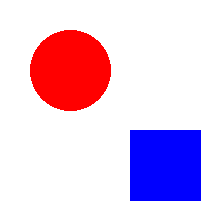

⏱️ image_chat 耗时: 2.40 秒
── 模型回复 ──
图里包含以下形状和颜色：

- **红色圆形**
- **蓝色正方形**

所以，图中有两种形状：一个红色圆和一个蓝色正方形。



In [12]:
# ============ 5. 图像理解（多模态） ============
from PIL import Image, ImageDraw
from IPython.display import display

# ① 造一张测试图：红圆 + 蓝方块
img = Image.new("RGB", (224, 224), "white")
draw = ImageDraw.Draw(img)
draw.ellipse((30, 30, 110, 110), fill="red")
draw.rectangle((130, 130, 200, 200), fill="blue")
display(img)


@timer
def image_chat(image, question):
    # ② 多模态消息：图像 + 问题
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {"type": "text", "text": question},
            ],
        }
    ]
    prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

    # ③ 多模态处理：text 和 images 都要传
    inputs = processor(text=[prompt], images=[image], return_tensors="pt").to(model.device)

    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=128, do_sample=False)

    reply = processor.tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return reply


reply = image_chat(img, "图里有哪些形状？分别是什么颜色？")
print("── 模型回复 ──")
print(reply)

## 小结与延伸

- 本机全链路已跑通：**分词 → 加载 → 文本生成 → 图像理解**，全部本地推理、不联网
- 加载要点：直接传本地目录（`MODEL_DIR`）；`dtype="auto"` + `device_map="auto"` 是 6GB 显存跑起 2B 模型的关键
- 继续玩：
  - 把测试图换成自己的照片 / 屏幕截图，试描述、OCR、数数
  - 试玩 `pipeline` 封装与零样本目标检测（OWL-ViT 之类）
  - 进阶：vLLM / llama.cpp 提吞吐，或参考 week15 的套路包成 FastAPI 服务